<a href="https://colab.research.google.com/github/DanDC25/Statistical-Learning-with-Python/blob/main/%5BPractice_CV_%2B_CV_min_%2B_CV_1SE_%2B_Touch_once_%26_Refit_%2B_degrees_R%5E2%5D_DSA211_Simulated_Q3_Cross_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## How to use this question

This question is built from **Lab 7 (Cross-Validation Pipelines)** on the same `Auto` data, with the one-standard-error rule from **Lab 8** and the one-test-touch step from **Lab 9**. Every step has been done in a lab.

- Work like the exam: about **18 minutes**, open book, no AI.
- For each part, find the matching lab cell, adapt the code, run it, then write your answer in the markdown cell under the part label.
- Keep to the sentence limits. A printed number with no sentence earns at most half the marks.
- Importing the libraries you need is part of the task. The **📍 Where to look** note under each part says which lab cell to open, including the Setup cells with the imports. Try first, then look.

***

## Setup

Run as given. It loads `Auto` exactly as in Lab 7, Part 0, and makes one 70/30 split. Use `X_tr`, `y_tr` for every choice, and touch `X_te`, `y_te` once, in 3(d).

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split

url = 'https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/Auto.csv'
Auto = pd.read_csv(url)
Auto.index = range(1, len(Auto) + 1)

X = Auto[['horsepower']]
y = Auto['mpg']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=2026)

print(f"Training rows: {len(y_tr)}, test rows: {len(y_te)}")

Training rows: 274, test rows: 118


Use `KFold(n_splits=5, shuffle=True, random_state=2026)` for every CV in this question.

***

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
from scipy import stats as scipy_stats
from statsmodels.graphics.regressionplots import plot_partregress_grid

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, LeaveOneOut, KFold, StratifiedKFold,
                                     cross_val_score, cross_validate, cross_val_predict)
from sklearn.metrics import mean_squared_error, confusion_matrix, RocCurveDisplay
# add more as needed



**3(a)** Fit a straight line, `mpg` on `horsepower`, to the training set with `statsmodels`, and plot its residuals against its fitted values. What does the plot show, and what does it suggest adding to the model? **[2]** *(at most 2 sentences)*

[Text(0.5, 0, 'Fitted values'),
 Text(0, 0.5, 'Residuals'),
 Text(0.5, 1.0, '1. Residuals vs Fitted')]

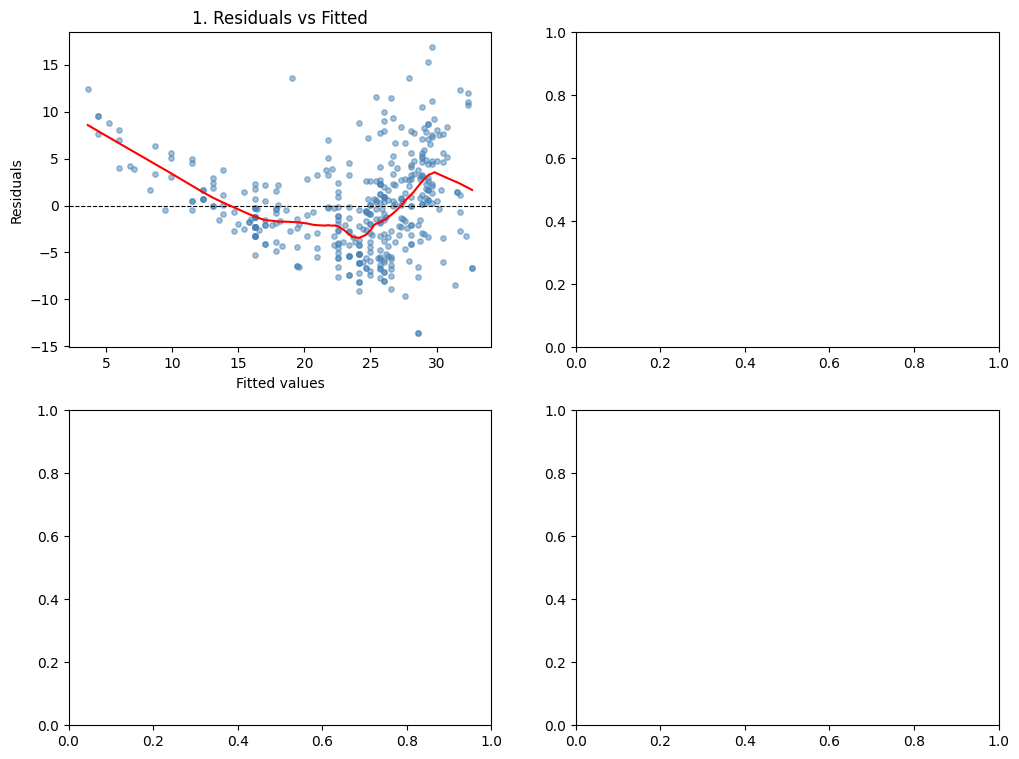

In [30]:
### YOUR CODE HERE
model = sm.OLS(y, sm.add_constant(X)).fit()

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fitted    = model.fittedvalues
residuals = model.resid
ax = axes[0, 0] # position
ax.scatter(fitted, residuals, alpha=0.5, s=15, color='steelblue')
ax.axhline(0, color='black', lw=0.8, ls='--')
lo = sm.nonparametric.lowess(residuals, fitted, frac=0.3) # lowess
ax.plot(lo[:, 0], lo[:, 1], color='red', lw=1.5)
ax.set(xlabel="Fitted values", ylabel="Residuals", title="1. Residuals vs Fitted")


**3(a)**

*Your answer here:*

The Residual-Fitted plot shows that the red lowess line is not horizontal at Residual = 0, but rather a curved U-shape as fitted values increase. The Residual-Fitted plot suggests that there is a non-linear relationship between horsepower and mpg, and that a non-linear term should be added to horsepower to amend for the non-linear relationship.

> 📍 **Where to look**
>
> - **Imports:** Lab 7, **Part 0: Setup and Data** (first code cell).
> - **Fit:** Lab 7, **Exercise 2.1** (`sm.OLS(y, sm.add_constant(X))`). Use the training rows only.
> - **Plot:** Lab 4, **Part 2**, panel 1 of the four-plot cell (residuals against fitted values, with the LOWESS line). The scatter at the end of Lab 7 **Part 0** shows the same shape in the raw data.

***

**3(b)** Using a polynomial pipeline, compute the 5-fold CV MSE on the training set for degrees 1 to 6, together with the standard error of each CV MSE. Report the table. **[2]** *(at most 1 sentences)*

In [61]:
### YOUR CODE HERE
poly_pipe = Pipeline([('scale', StandardScaler()),
                      ('poly',  PolynomialFeatures(include_bias=False)),
                      ('ols',   LinearRegression())])

degrees = range(1, 7)
kf = KFold(n_splits=5, shuffle=True, random_state=2026)

cv_mse = []
se_degrees_score = []
# change the polynomial degree with set_params: step name + __ + parameter
# e.g. poly_pipe.set_params(poly__degree=3)
for d in degrees:
    poly_pipe.set_params(poly__degree=d)
    scores = cross_val_score(poly_pipe,
                             X_tr,
                             y_tr,
                             cv=kf,
                             scoring='neg_mean_squared_error')
    cv_mse.append(-scores.mean())
    se_score = scores.std(ddof=1) / np.sqrt(len(scores))
    se_degrees_score.append(se_score)
results = pd.DataFrame({'degree': degrees,
                        'cv_mse_k5': np.round(cv_mse, 2),
                        'standard_error': np.round(se_degrees_score, 4)})
print(results.to_string(index=False))

 degree  cv_mse_k5  standard_error
      1      24.28          1.8881
      2      19.43          1.7612
      3      19.66          1.6944
      4      19.96          1.5881
      5      19.84          1.4772
      6      19.75          1.5780


**3(b)**

*Your answer here:*

From the printed table above, it appears that CV MSE has a negative relationship whereas standard error has a positive relationship as the polynomial degree for the model increases.

> 📍 **Where to look**
>
> - **Code:** Lab 7, **3.1 k-Fold CV with MSE as the Scoring** (the `poly_pipe` pipeline and the degree loop) and **Exercise 3.1** (the same loop with 5 folds). Keep each degree's five fold scores, not only their mean.
> - **SE:** Lab 8, **Part 4: Cross-Validation for Model Selection**, the cell starting `kf = KFold(` (the `cv_se` line, `ddof=1`, divided by $\sqrt{K}$).

***

**3(c)** Which degree minimises CV MSE, and which degree does the one-standard-error rule select? Which do you carry forward, and why? **[2]** *(at most 3 sentences)*

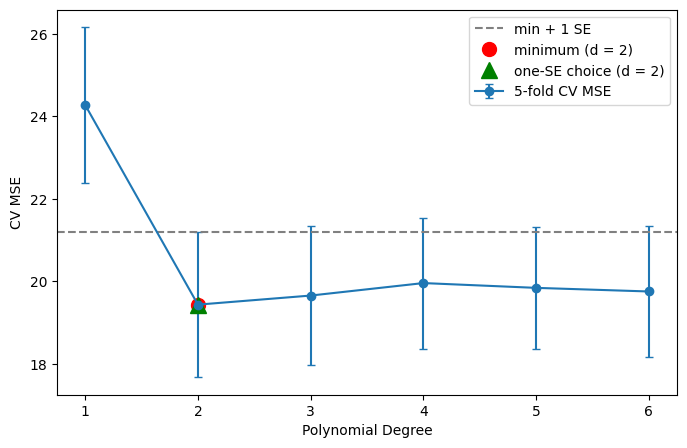

CV MSE is minimised at degree: 2 (MSE = 19.43)
1-SE threshold is: 21.20
The one-standard-error rule selects degree: 2 (MSE = 19.43)


In [60]:
### YOUR CODE HERE

cv_mse = []
se_degrees_score = []

for d in degrees:
    poly_pipe.set_params(poly__degree=d)
    scores = cross_val_score(poly_pipe,
                             X_tr,
                             y_tr,
                             cv=kf,
                             scoring='neg_mean_squared_error')
    cv_mse.append(-scores.mean())
    se_score = scores.std(ddof=1) / np.sqrt(len(scores))
    se_degrees_score.append(se_score)

cv_means = np.array(cv_mse)
cv_ses = np.array(se_degrees_score)

idx_min = np.argmin(cv_means)
k_min = degrees[idx_min]
threshold = cv_means[idx_min] + cv_ses[idx_min]

# Find the simplest model (lowest degree) within 1 SE of the minimum
idx_1se = np.where(cv_means <= threshold)[0][0]
k_1se = degrees[idx_1se]

plt.figure(figsize=(8, 5))
plt.errorbar(degrees,
             cv_means,
             yerr=cv_ses,
             fmt='o-',
             capsize=3,
             label='5-fold CV MSE')
plt.axhline(threshold,
            color='grey',
            linestyle='--',
            label='min + 1 SE')
plt.plot(k_min, cv_means[idx_min],
         'ro',
         markersize=10,
         label=f'minimum (d = {k_min})')
plt.plot(k_1se, cv_means[idx_1se],
         'g^',
         markersize=12,
         label=f'one-SE choice (d = {k_1se})')
plt.xticks(degrees)
plt.xlabel('Polynomial Degree')
plt.ylabel('CV MSE')
plt.legend()
plt.show()

print(f"CV MSE is minimised at degree: {k_min} (MSE = {cv_means[idx_min]:.2f})")
print(f"1-SE threshold is: {threshold:.2f}")
print(f"The one-standard-error rule selects degree: {k_1se} (MSE = {cv_means[idx_1se]:.2f})")

**3(c)**

*Your answer here:*

Because the one-standard error rule chooses degree 2 which is also the degree with minimum CV MSE. Hence, the one-SE rule does not have to give up anything as degree two is the most optimal given the one-SE rule and the minimum CV MSE rule.



> 📍 **Where to look**
>
> - **Code:** Lab 8, **4.1 The One-Standard-Error Rule** (the `threshold = ...` and `k_1se` cell). Here "size" is the polynomial degree.
> - **Reasoning:** Lab 8, **Exercise 4.1** and **Question 4.1** (what the one-SE rule gives up), and Lab 7, **Question 3.1a** (read the shape of the CV curve, not just its minimum).

***

**3(d)** Touch the test set once with your carried-forward degree and report the test MSE. Compare it with that degree's CV MSE. If you then refit the same degree on all 392 cars, what figure would you report as its expected prediction error, and why? **[2]** *(at most 3 sentences)*

In [69]:
### YOUR CODE HERE
# Define the Degree 2 pipeline
poly_pipe_d2 = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ols', LinearRegression())
])
poly_pipe_d2.fit(X_tr, y_tr)

kf = KFold(n_splits=5, shuffle=True, random_state=2026)
cv_scores = -cross_val_score(poly_pipe_d2, X_tr, y_tr, cv=kf, scoring='neg_mean_squared_error')
cv_mse_d2 = cv_scores.mean()

test_mse_d2 = mean_squared_error(y_te, poly_pipe_d2.predict(X_te))
poly_pipe_d2.fit(X, y)

error = pd.DataFrame({
    'CV MSE (Training Set)': cv_mse_d2,
    'Test MSE': test_mse_d2,
}, index=['Degree 2'])
print(f'Results for the Degree 2 polynomial model:\n{error.to_string()}')

Results for the Degree 2 polynomial model:
          CV MSE (Training Set)   Test MSE
Degree 2              19.434744  19.525019


Touch the test set once with your carried-forward degree and report the test MSE. Compare it with that degree's CV MSE. If you then refit the same degree on all 392 cars, what figure would you report as its expected prediction error, and why?

**3(d)**

*Your answer here:*

After touching the test set once with the carried-forward degree 2, the OLS test MSE isn't significantly larger than the CV MSE from the training set. At degree 2 on the test set, the MSE is 19.525019, whereas the CV MSE on the training set is 19.434744. If I refit the same degree on all 392 cars, I would report the Test MSE of the as it utilizes the test-set that has only been touched **once** which provides an ubniased estimate of how the model generalizes on unseen data.


> 📍 **Where to look**
>
> - **Code:** Lab 9, **Exercise 4.2: One test touch, two final refits** (fit on the training set, score the test set once).
> - **Reasoning:** Lab 9, **Question 4.2b**, and the Lab 9 introduction: split once, decide by CV on the training set, touch the test set once, refit on all the data.

***

**3(e)** For your carried-forward degree, report the 5-fold CV $R^2$ and the training $R^2$ from the same call. Interpret the CV $R^2$ in one sentence, and explain why the gap between the two is small here. **[2]** *(at most 2 sentences)*

In [85]:
### YOUR CODE HERE

poly_pipe = Pipeline([('scale', StandardScaler()),
                      ('poly',  PolynomialFeatures(include_bias=False)),
                      ('ols',   LinearRegression())])

kf = KFold(n_splits=5, shuffle=True, random_state=2026)
cv_mse = []

poly_pipe.set_params(poly__degree=2)
r2 = cross_validate(poly_pipe, X_tr, y_tr, cv=kf,
                   scoring=['neg_mean_squared_error', 'r2'], return_train_score=True)

mean_test_r2 = r2['test_r2'].mean()
mean_train_r2 = r2['train_r2'].mean()

results = pd.DataFrame({
    'Mean train R^2' :  mean_train_r2,
    'Mean test R^2' :  mean_test_r2,
}, index=[0])

print(results.to_string(index=False))
print(f'\nThe mean train R^2 is {mean_train_r2:.3f} and test R^2 is {mean_test_r2:.3f}.')


 Mean train R^2  Mean test R^2
       0.687185        0.66406

The mean train R^2 is 0.687 and test R^2 is 0.664.


**3(e)**

*Your answer here:*

The average 5 fold CV R^2 is 0.66406 implies that using the 5-fold cross validation on the test set, the model explains 66.4% of the total variance of the dataset, whereas the average R^2 on the training is 0.687185. The gap between the 2 R^2 value is small here because the model is relatively simple with 2 polynomial degrees and 1 parameter; hence, the model doesn't struggle with overfitting nor underfitting.



> 📍 **Where to look**
>
> - **Code:** Lab 7, **Exercise 3.2: MSE and R² in one call** (`cross_validate` with a list of scorers and `return_train_score=True`).
> - **Reasoning:** Lab 7, **Question 3.2**. How many parameters does your model have, against how many training rows?

***

## After you finish

Check yourself against the lab:

1. Did every figure you quoted come from your own printed output?
2. Did every part get a written answer, not only code?
3. Which parts needed the lab open? Those cells are the ones to rehearse before the exam.